<div align="center">
    
# ΠΑΝΕΠΙΣΤΗΜΙΟ ΚΡΗΤΗΣ
# Τμήμα Επιστήμης Υπολογιστών

## HY-112: Φυσική Ι
## Χειμερινό Εξάμηνο 2024-2025
### Διδάσκων: Γ. Καφεντζής

## Ανάθεση: 19-11-2024
## Παράδοση (ηλεκτρονικά, όπως αναφέρεται στο τέλος του αρχείου): 
## Κυριακή, 30-11-2024, 23:59:59

Σε αυτο το τέταρτο "εργαστήριο" του μαθήματος θα πειραματιστούμε με 

(α) την αρχή διατήρησης της ενέργειας, 

(β) με ταλαντωτές και τις συναρτήσεις που τους περιγράφουν, και 

(γ) με το φαινόμενο του συντονισμού στις εξαναγκασμένες ταλαντώσεις

Σε κάθε πρόγραμμα Python που γράφουμε, στις πρώτες γραμμές εισάγουμε όποιες βιβλιοθήκες σκοπεύουμε να χρησιμοποιήσουμε. 

Ας ξεκινήσουμε εισάγοντας τις γνωστές μας βιβλιοθήκες, και κάποιες βολικές συντομεύσεις τους. Εκτελέστε το παρακάτω κομμάτι κώδικα επιλέγοντάς το και πατώντας Shift + Enter.

In [ ]:
import numpy as np                     # Βιβλιοθήκη numpy, θα τη "φωνάζουμε" ως np στο εξής.
import matplotlib.pyplot as plt        # Θέλουμε μόνο την pyplot συνάρτηση της βιβλιοθήκης matplotlib και θα τη "φωνάζουμε" plt.
import pandas as pd                    # Βιβλιοθήκη pandas για ανάγνωση αρχείων, θα τη "φωνάζουμε" pd.
import scipy                           # Βιβλιοθήκη scipy για επιστημονικούς υπολογισμούς, έχει ωραίες έτοιμες συναρτήσεις.
from scipy import signal               # Μια συγκεκριμένη υποβιβλιοθήκη της scipy.
from scipy.io import wavfile           # Υποβιβλίοθηκη για ανάγνωση .WAV αρχείων.
import scipy.io                        # Υποβιβλιοθήκη για input/output.
%matplotlib inline                     

# Άσκηση Python 1

Σε αυτήν την άσκηση θα επιβεβαιώσουμε αριθμητικά την Αρχή Διατήρησης της Ενέργειας (ΑΔΕ)! Έχετε ήδη δει στη θεωρία σας πόσο χρήσιμα είναι τέτοια ενεργειακά θεωρήματα στη λύση πολύπλοκων προβλημάτων. 

Ας υποθέσουμε ότι έχουμε μια μπάλα, την οποία πετάμε κατακόρυφα προς τα πάνω με αρχική ταχύτητα $u_0$. Σύστημά μας θα είναι η μπάλα και η Γη (διμελές). Θεωρώντας λοιπόν ότι οι αντιστάσεις του αέρα είναι αμελητέες, τότε το σύστημα είναι απομονωμένο, ενώ οι δυνάμεις που παράγουν έργο στα δυο σώματα του συστήματος είναι συντηρητικές (μόνο η βαρυτική δύναμη!). Προφανώς μας ενδιαφέρει μόνο το ένα μέλος του συστήματος: η μπάλα.

Μπορούμε λοιπόν να εφαρμόσουμε μια ειδική περίπτωση της ΑΔΕ, την **Αρχή Διατήρησης της Μηχανικής Ενέργειας (ΑΔΜΕ)**!

Η ΑΔΜΕ διατυπώνεται ως 

$$U_g^A + K^A = U_g^B + K^B$$

με $U_g, K$ η βαρυτική δυναμική και η κινητική ενέργεια του συστήματος, αντίστοιχα, και $^A, ^B$ δυο στιγμιότυπα της κίνησης του συστήματος, δηλ. μια αρχική και μια τελική θέση. Ας θεωρήσουμε ότι όταν η μπάλα ακουμπά στη Γη, τότε η διάταξη του συστήματος είναι διάταξη μηδενικής βαρυτικής δυναμικής ενέργειας. Όπως ήδη γνωρίζετε

\begin{align}
K &=  \frac{1}{2}mu^2 \\
U_g &= mgy
\end{align}

με $m, u, y$ η μάζα της μπάλας, η ταχύτητά της (κατά μέτρο), και η απόστασή της από την επιφάνεια της Γης, αντίστοιχα. 

Στην άσκησή μας θέλουμε να κάνουμε το εξής: θέλουμε να μπορούμε να ελέγχουμε διαφορετικά στιγμιότυπα της κίνησης του συστήματος και να μπορούμε να επιβεβαιώνουμε ότι ισχύει η ΑΔΜΕ για αυτά τα στιγμιότυπα. Άρα θέλουμε να μπορούμε να βρίσκουμε τις παραπάνω ενέργειες για όποια χρονική στιγμή - στιγμιότυπο θέλουμε! Ας μετατρέψουμε λοιπόν τις παραπάνω ενέργειες με βάση τις σχέσεις της κατακόρυφης κίνησης (ευθύγραμμης ομαλά επιταχυνόμενης)

\begin{align}
y(t) &= u_0 t - \frac{1}{2}gt^2 \\
u(t) &= u_0 - gt
\end{align}

οι οποίες μας δίνουν

\begin{align}
K(t) &= \frac{1}{2}m(u_0 - gt)^2 \\
U_g(t) &= mg\left(u_0t - \frac{1}{2}gt^2\right)
\end{align}

Για ευκολία, θα μελετήσουμε την κίνηση της μπάλας μέχρι να φτάσει στο μέγιστο ύψος, δηλ. μέχρι όταν

$$0 = u_0 - gt \Longleftrightarrow t = \frac{u_0}{g}$$

Θα χρησιμοποιήσουμε μια **γεννήτρια τυχαίων αριθμών** για να πάρουμε $N$ τυχαίες χρονικές στιγμές, τις οποίες θα χρησιμοποιούμε σε ζεύγη (ως ζεύγη στιγμιοτύπων Α, Β) και θα γράψουμε ένα πρόγραμμα που λαμβάνει αυτές τις στιγμές και μας πληροφορεί αν ισχύει η ΑΔΜΕ!

Ένα ερώτημα που σίγουρα έχετε είναι **πως** θα παράξουμε τυχαίους αριθμούς. Δε θα μπούμε σε λεπτομέρειες αλλά θα βασιστούμε σε έτοιμες συναρτήσεις της βιβλιοθήκης ``numpy``. Δείτε πως:

In [ ]:
N = 100     # 100 χρονικές στιγμές.
tlow = 0    # Κάτω όριο τυχαίου αριθμού.
thigh = 10  # Άνω όριο τυχαίου αριθμού.
rn = np.random.uniform(tlow, thigh, N)  # Παίρνουμε N τιμές στο διάστημα [0,10), με ίδια πιθανότητα επιλογής.
print(f"Οι τυχαίαι αριθμοί που επιλέχθηκαν είναι {rn}")

Παρατηρήστε προσεκτικά την κλήση της συνάρτησης ``uniform`` της βιβλιοθήκης ``random`` της ``numpy``. Κάθε τιμή μεταξύ $[\textrm{tlow, thigh})$ (στην παραπάνω περίπτωση, $[0,10)$) έχει την ίδια πιθανότητα να επιλεγεί από τη συνάρτηση ``random``: λέμε ότι οι τιμές που επιστρέφει η συνάρτηση επιλέγονται από **ομοιόμορφη κατανομή** στο διάστημα $[\textrm{tlow, thigh})$.

## Ζητούμενο 1:

Γράψτε συνάρτηση ``get_rand_nums(N, u0)`` που υπολογίζει ``N`` τυχαίους αριθμούς στο διάστημα $[\textrm{tlow, thigh}) = \left[0, \frac{u_0}{g}\right)$.

In [ ]:
def get_rand_nums(N, u0):
    g = 9.8
    # Γράψτε κώδικα 
    tlow = 0   # Κάτω όριο.
    thigh = u0 / g;   # Άνω όριο υπολογιζόμενο από u0 / g.
    rn = np.random.uniform(tlow, thigh, N)   # Δημιουργία Ν τυχαίων αριθμών στο [tlow, thigh) = [0, u0/g).
    return rn
# Τέλος κώδικα

Ας την ελέγξουμε:

In [ ]:
N = 50
rn = get_rand_nums(N, 19.6)        # Θα πρέπει να παίρνετε αριθμούς στο διάστημα [0,2).
print(rn)                          # Οι αριθμοί θα είναι διαφορετικοί για τον/την καθένα/μια από σας (λόγω τυχαιότητας) αλλά πρέπει να ανήκουν πάντα στο [0,2)!

Αφού έχετε τη γεννήτρια των τυχαίων χρονικών στιγμών, μπορείτε να γράψετε συνάρτηση που υπολογίζει αν η Μηχανική Ενέργεια τη μια χρονική στιγμή ισούται με τη Μηχανική Ενέργεια σε μια άλλη χρονική στιγμή. Μπορείτε να θεωρήσετε ότι οι πρώτες $N/2$ χρονικές στιγμές θα χρησιμοποιηθούν για να διαλέξουμε ένα στιγμιότυπο της κίνησης του συστήματος, ενώ υπόλοιπες $N/2$ χρονικές στιγμές θα χρησιμοποιηθούν για ένα άλλο στιγμιότυπό της.

**Προσέξτε** όμως! Λόγω πολύ μικρών αριθμητικών σφαλμάτων που αναπόφευκτα υπάρχουν όταν κάνουμε πράξεις στον υπολογιστή (λόγω πεπερασμένης ακρίβειας), δεν πρέπει να ελέγξετε αν οι δυο μηχανικές ενέργειες είναι ίσες με το συνήθη τρόπο που ξέρετε από τα προγραμματιστικά μαθήματα, καθώς πολύ πιθανό να διαφέρουν στο 6ο, 7ο, 10ο ή και μεγαλύτερο δεκαδικό ψηφίο. Γενικότερα, έλεγχος για ισότητα μεταξύ δεκαδικών αριθμών **ΔΕΝ** πρέπει να γίνεται με τον κλασικό τελεστή $==$.

Πώς μπορούμε να ξεπεράσουμε αυτό το *εγγενές* πρόβλημα στους υπολογισμούς μας? Θα θεωρούμε ότι δυο δεκαδικοί αριθμοί είναι ίσοι αν **η απόλυτη διαφορά τους** είναι μικρότερη από έναν ***πολύ*** μικρό αριθμό $\epsilon$:

$$|number_1 - number_2| < \epsilon$$

Βλέπετε ότι κάθε πρόβλημα που λύνουμε μας εμφανίζει ένα άλλο! Ποιός είναι αυτός ο αριθμός $\epsilon$ και πόσο μικρός πρέπει να είναι? Συνήθως ορίζουμε εμείς τον αριθμό $\epsilon$, και τον ονομάζουμε **απόλυτη ανοχή (absolute tolerance)**. Μια τιμή της τάξης του $10^{-10}$ είναι συνηθως αποδεκτή.

Πριν λοιπόν γράψετε τη συνάρτηση που ελέγχει την ΑΔΜΕ, σας δίνεται μια βοηθητική συνάρτηση που ελέγχει αν δυο **λίστες** έχουν ίσες τιμές (μια προς μια), με βάση το κριτήριο απόλυτης ανοχής, και επιστρέφει ένα λογικό διάνυσμα True/False, ανάλογα με το αποτέλεσμα της σύγκρισης.

In [ ]:
def check_float_equality(n1, n2):
    
    epsilon = 10 ** (-10)   # Όριο σφάλματος μεταξύ δυο δεκαδικών (δέκα εις τη μείον 10).
    check = (np.abs(np.array(n1) - np.array(n2)) < epsilon)   # Έλεγχος απόλυτης ανοχής.
    
    return check.tolist()   # *Μετατροπή σε πιο ευανάγνωστη (και απαιτούμενη) έξοδο.

Ας την ελέγξουμε:

In [ ]:
check1 = check_float_equality([0.1, 0.2], [0.1, 0.4])
check2 = check_float_equality([0.11, 0.2], [0.1, 0.4])
check3 = check_float_equality([0.1, 0.399999999999], [0.1, 0.4])
check4 = check_float_equality([0.099, 0.4000000000001], [0.1, 0.4])

print(check1, check2, check3, check4)   # *Πρέπει να επιστρέφει:  [True, False] [False, False] [True, True] [False, True]

Τώρα μπορούμε να γράψουμε τη συνάρτηση ελέγχου της ΑΔΜΕ.

## Ζητούμενο 2:

Συμπληρώστε την παρακάτω συνάρτηση η οποία υπολογίζει τη Μηχανική Ενέργεια σε δυο στιγμιότυπα της κίνησης και ελέγχει αν ισχύει αυτή:

In [ ]:
def check_ADME(N, m, u0):

    g = 9.8   # Επιτάχυνση της βαρύτητας.

    rn = get_rand_nums(N, u0)   # Επιλέγουμε Ν τυχαίες χρονικές στιγμές στο διάστημα [0,u0/g).
    t1 = rn[0:int(N/2)]         # Οι πρώτες Ν/2 αντιστοιχούν σε χρονικές στιγμές t1.
    t2 = rn[int(N/2):]          # Οι επόμενες Ν/2 αντιστοιχούν σε χρονικές στιγμές t2.

    K1 = 0.5 * m * (u0 - g * np.array(t1)) ** 2                       # Κινητική ενέργεια Κ1 για κάθε χρονική στιγμή t1.
    Ug1 = m * g * (u0 * np.array(t1) - 0.5 * g * np.array(t1) ** 2)   # Βαρυτική δυναμική ενέργεια Ug1 για κάθε χρονική στιγμή t1.
    M1 = K1 + Ug1                                                     # Μηχανική Ενέργεια Μ1 για κάθε χρονική στιγμή t1.

    K2 = 0.5 * m * (u0 - g * np.array(t2)) ** 2                       # Κινητική ενέργεια K2 για κάθε χρονική στιγμή t2.
    Ug2 = m * g * (u0 * np.array(t2) - 0.5 * g * np.array(t2) ** 2)   # Βαρυτική δυναμική ενέργεια Ug2 για κάθε χρονική στιγμή t2.
    M2 = K2 + Ug2                                                     # Μηχανική Ενέργεια Μ2 για κάθε χρονική στιγμή t2.

    check = check_float_equality(M1, M2)    # Έλεγχος ισότητας μεταξύ των Μηχανικών Ενεργειών Μ1, Μ2.

    return check

Ας δούμε αν ισχύει η ΑΔΜΕ στο πρόβλημά μας!

In [ ]:
N = 100   # Αριθμός χρονικών στιγμών.
m = 2.0   # Μάζα 2 kg.
u0 = 4.5;   # Αρχική ταχύτητα ρίψης μπάλας 4.5 m/s.
ADME = check_ADME(N, m, u0)   # Έλεγχος ΑΔΜΕ.
for j in range(0, int(N/2)):
    print("Στιγμιότυπο {}: {}".format(j, ADME[j]))  # Πρέπει όλα να βγαίνουν "True" και άρα να ισχύει η ΑΔΜΕ για κάθε χρονική στιγμή !

# Άσκηση Python 2

Στην άσκηση αυτή, θα μελετήσουμε αριθμητικά ταλαντωτές και θα κάνουμε τις γραφικές παραστάσεις της κίνησής τους.

Υποθέστε ότι στο αρχείο $\textrm{oscillator.csv}$ έχετε καταγράψει τη θέση $x(t)$ ενός απλού αρμονικού ταλαντωτή σε $1000$ χρονικές στιγμές. Θέλετε να τυπώσετε τις τρεις γραφικές παραστάσεις που μάθατε στη θεωρία: **θέση, στιγμαία ταχύτητα, στιγμιαία επιτάχυνση**.

Πώς μπορούμε να απεικονίσουμε τις γραφικές παραστάσεις κατευθείαν από τα δεδομένα μας? (χωρίς να χρειαστεί να βρούμε από αυτά το πλάτος $A$, τη συχνότητα $\omega$, και την αρχική φάση $\phi$, μέσω κάποιας μοντελοποίησης, και στη συνέχεια να χρησιμοποιήσουμε το τυπολόγιό μας)

Ας διαβάσουμε το αρχείο και ας απεικονίσουμε τη συνάρτηση θέσης $x(t)$.

In [ ]:
data = pd.read_csv('./oscillator.csv', header=None)
t = data[0]
x = data[1]

plt.figure(figsize=(8, 6))
plt.plot(t, x)
plt.xlabel('Χρόνος (s)')
plt.ylabel('x(t)')
plt.title('Ταλαντωτής')
# plt.show()

Ευτυχώς ξέρουμε ότι η θέση, η στιγμαία ταχύτητα, και η στιγμιαία επιτάχυνση σχετίζονται μεταξύ τους με παραγώγους! : 

\begin{align}
u(t) &= \frac{d}{dt}x(t) \nonumber \\
a(t) &= \frac{d^2}{dt^2}x(t) = \frac{d}{dt}u(t) \nonumber
\end{align}

Άρα μπορούμε να βρούμε τις ζητούμενες σχέσεις και τις αντίστοιχες γραφικές παραστάσεις αν *απλά* παραγωγίσουμε τη συνάρτηση θέσης $x(t)$, που ήδη έχουμε στα χέρια μας!

Το ερώτημα είναι **πως παραγωγίζουμε μια συνάρτηση στον υπολογιστή?**

Ας σκεφτούμε τον ορισμό της παραγώγου:

$$f'(t) = \lim_{t\to t_0} \frac{f(t) - f(t_0)}{t-t_0} $$

Προφανώς δεν μπορούμε να εφαρμόσουμε τη σχέση αυτή στη δική μας περίπτωση γιατί ***δεν*** έχουμε μια συνεχή συνάρτηση στα χέρια μας: έχουμε απλά τιμές της ανά τακτά χρονικά διαστήματα. 

Ο εναλλακτικός ορισμός της παραγώγου θα μας φανεί πιο χρήσιμος:

$$f'(t) = \lim_{h \to 0} \frac{f(t+h) - f(t)}{h} $$

Τι είναι η μεταβλητή $h$ στην περίπτωσή μας? Είναι μια απειροστά μικρή απόσταση στο πεδίο ορισμού της συνάρτησης $f$. Η πιο μικρή απόσταση που έχουμε στα δεδομένα μας είναι μεταξύ δυο διαδοχικών χρονικών μετρήσεων της κίνησης του ταλαντωτή, δηλ. 

$$h = t_i - t_{i-1}, \: \: \forall i \in \mathbb{Z}$$

Επίσης, τι μας λέει ο αριθμητής στο παραπάνω όριο? Μας λέει ότι πρεπει να πάρουμε τη διαφορά μεταξύ δυο **πολύ** κοντινών τιμών της συνάρτησης $f$. Μα οι πιο κοντινές τιμές που έχουμε στην περίπτωσή μας είναι μεταξύ δυο διαδοχικών μετρήσεων της συνάρτησης θέσης $x(t)$!

Μπορούμε λοιπόν να προσεγγίσουμε την παράγωγο μιας συνάρτησης σε ένα χρονικό σημείο $t_i$ ως

$$f'(t_i) \approx \frac{f(t_i) - f(t_{i-1})}{t_i - t_{i-1}}, \: i = 1, \cdots, N$$

με $N$ το πλήθος των μετρήσεων που έχουμε στον υπολογιστή μας.

Αυτός ο τρόπος προσέγγισης της παραγώγου ονομάζεται **διακριτή παραγώγιση (discrete differentiation)**.

Για να δούμε αν δουλεύει η μέθοδος!

In [ ]:
dt = t[1] - t[0]         # Διαφορά μεταξύ διαδοχικών χρονικών στιγμών (προσομοίωση του h) - μπορούμε...
                         # να χρησιμοποιήσουμε οποιεσδήποτε διαδοχικές χρονικές στιγμές, π.χ. t[20]-t[19].
dx = np.diff(x)          # Συνάρτηση που υπολογίζει τη διαφορά μεταξύ...
                         # διαδοχικών τιμών ενός array (υπολογισμός του f(t(i)) - f(t(i-1)).
u = dx / dt              # 1η παράγωγος.
ddx = np.diff(x, 2)      # Διπλή εφαρμογή της διαφοράς.
a = ddx / (dt * dt)      # 2η παράγωγος.

plt.figure(figsize=(14, 10))
plt.subplot(3, 1, 1)
plt.plot(t, x)
plt.ylabel('x(t)')
plt.xlabel('Χρόνος (s)')
plt.subplot(3, 1, 2)
plt.plot(t[1:], u, 'r')
plt.ylabel('u(t)')
plt.xlabel('Χρόνος (s)')
plt.subplot(3, 1, 3)
plt.plot(t[2:], a, 'g')
plt.ylabel('a(t)')
plt.xlabel('Χρόνος (s)')
# plt.show()

## Ζητούμενο:

Επαναλάβετε την παραπάνω διαδικασία για έναν φθίνοντα ταλαντωτή της μορφής

$$x(t) = Ae^{-\lambda t}\cos(\omega_0 t + \phi)$$

του οποίου τη θέση $x(t)$ έχετε στην τρίτη στήλη του αρχείου $\textrm{oscillator.csv}$ παραπάνω.

In [ ]:
t = data[0]                   # Χρόνος - 1η στήλη του αρχείου σας.
xdec = data[2]                # Θέση - 3η στήλη του αρχείου σας.
dt = t[1] - t[0]              # Διαφορά μεταξύ διαδοχικών χρονικών στιγμών (προσομοίωση του h).
dxdec = np.diff(xdec)         # Συνάρτηση που υπολογίζει τη διαφορά μεταξύ διαδοχικών τιμών ενός array (υπολογισμός του f(ti) - f(t(i-1))).
udec = dxdec / dt             # 1η παράγωγος.
ddxdec = np.diff(xdec, 2)     # Διπλή εφαρμογή της διαφοράς.
adec = ddxdec / (dt ** 2)     # 2η παράγωγος.

plt.figure(figsize=(14, 10))
plt.subplot(3, 1, 1)
plt.plot(t, xdec)
plt.ylabel('x(t)')
plt.xlabel('Χρόνος (s)')
plt.subplot(3, 1, 2)
plt.plot(t[1:], udec, 'r')
plt.ylabel('u(t)')
plt.xlabel('Χρόνος (s)')
plt.subplot(3, 1, 3)
plt.plot(t[2:], adec, 'g')
plt.ylabel('a(t)')
plt.xlabel('Χρόνος (s)')
# plt.show()

# Άσκηση Python 3

Στην διάλεξη περί αρμονικών ταλαντώσεων μιλήσαμε πολύ επιγραμματικά για εξαναγκασμένες ταλαντώσεις, δηλ. φθίνουσες -κατ'αρχήν- ταλαντώσεις στις οποίες προσφέρουμε ενέργεια εξωτερικά ώστε να διατηρούμε τη Μηχανικη Ενέργεια του συστήματος του ταλαντωτή σε ένα συγκεκριμένο επίπεδο (π.χ. σπρώχνουμε περιοδικά την κούνια ώστε να διατηρήσουμε το πλάτος της ταλάντωσης σταθερό και τον αναβάτη χαρούμενο). Δεν πρόκειται να μπούμε σε ιδιαίτερες λεπτομέρειες σε αυτό το εργαστήριο αλλά είναι καλή ιδέα να δούμε μερικές εφαρμογές της θεωρίας αυτής.

Σχεδόν όλα τα σώματα τείνουν να δονούνται κατά κύριο λόγο σε συγκεκριμένη συχνότητα (ή συχνότητες) όταν τα χτυπάμε, τα τρίβουμε, τα τεντώνουμε και τ' αφήνουμε απότομα, τα διαταράσσουμε ξαφνικά κλπ. Οι συχνότητες αυτές καλούνται **φυσικές συχνότητες** ή **ιδιοσυχνότητες** των συγκεκριμένων σωμάτων. 

Στην εξαναγκασμένη ταλάντωση παρατηρήσαμε ότι συμβαίνουν φαινόμενα συντονισμού όταν η συχνότητα της εξωτερικής διέγερσης είναι *πολύ κοντινή ή ίση* με την ιδιοσυχνότητα του ταλαντωτή, με αποτέλεσμα τη μεγιστοποίηση του πλάτους ταλάντωσης. Ας πούμε μερικές λεπτομέρειες για αυτό το ενδιαφέρον φαινόμενο. Δείτε το παρακάτω σχήμα από τις διαλέξεις.

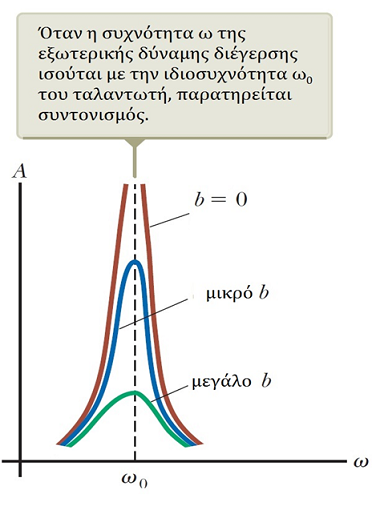

Θυμηθείτε τη συχνότητα $f$ που ορίσαμε στο μάθημα: μας πληροφορεί για το πλήθος των ταλαντώσεων που εκτελούνται σε ένα δευτερόλεπτο. Για παράδειγμα, συχνότητα $f=100$ Hz για έναν ταλαντωτή σημαίνει $100$ πλήρεις ταλαντώσεις σε ένα δευτερόλεπτο. Η συχνότητα $\omega$ είναι απλά $2\pi$ φορές η συχνότητα $f$. 

Κάθε ταλαντωτής μπορεί να ταλαντώνεται σε μία περιοχή συχνοτήτων (για παράδειγμα, μια τυπική κούνια του λούνα-παρκ δεν μπορεί να ταλαντώνεται σε συχνότητες μεγαλύτερες από περίπου $0.5$ Hz αλλά οι φωνητικές μας χορδές μπορούν να ταλαντώνονται με συχνότητες από $70$ ως $400$ Hz - ακόμα πιο πάνω μπορούν να φτάσουν οι επαγγελματίες σοπράνο, μέχρι τα $1500$ Hz!!!). 

Η στιγμιαία διέγερση ενός ταλαντωτή ισοδυναμεί με την απόδοση στην ταλάντωση ενός συγκεκριμένου ποσού ενέργειας (όταν, για παράδειγμα, συμπιέζουμε μέσω δύναμης $\vec{F_{ext}}$ ένα ελατήριο μεταφέροντας ενέργεια μέσω του έργου της $\vec{F_{ext}}$ στο σύστημα του ταλαντωτή). Αυτή είναι η απλή αρμονική ταλάντωση η οποία συμβαίνει με συχνότητα που ταυτίζεται με την ιδιοσυχνότητα του ταλαντωτή (ιδιοσυχνότητα $\omega_0 = \sqrt{\frac{k}{m}}$, στην περίπτωση ενός συστήματος ελατηρίου-σώματος). Όταν όμως η ταλάντωση είναι εξαναγκασμένη, η συχνότητα της είναι η συχνότητα του διεγέρτη, όπως είδαμε στο μάθημα. Όταν η συχνότητα του διεγέρτη ταυτίζεται με την ιδιοσυχνότητα του ταλαντωτή έχουμε το **φαινόμενο του συντονισμού**.

Κατά το συντονισμό, το σύστημα έχει το μέγιστο δυνατό πλάτος και τη μέγιστη δυνατή ενέργεια. Αν δεν υπάρχουν αποσβεστικές δυνάμεις (π.χ. αντίσταση του αέρα, τριβές, κλπ), τότε το πλάτος της ταλάντωσης γίνεται θεωρητικά άπειρο. Έτσι, η ταλάντωση μπορεί να γίνει τόσο έντονη, ώστε να καταστραφεί ο ταλαντωτής γιατί η προσφορά ενέργειας μέσω εξωτερικού έργου είναι μεν σταθερή αλλά η συνολική ενέργεια του ταλαντωτή γίνεται όλο και μεγαλύτερη (λόγω απουσίας αποσβεστικών δυνάμεων).

Για παράδειγμα, τα γυάλινα ή κρυστάλλινα ποτήρια έχουν μία συγκεκριμένη ιδιοσυχνότητα, η οποία μπορεί να ακουστεί αν τα χτυπήσουμε απαλά μία φορά. Αν εκπέμψουμε ήχο από ένα ηχείο σε αυτή τη συχνότητα, τότε το ποτήρι θα φτάσει να ταλαντεύεται με κάποιο μεγάλο πλάτος (προφανώς όχι άπειρο, αφού υπάρχουν στην πράξη αποσβεστικές δυνάμεις) μέχρι που το πλάτος θα γίνει πολύ μεγάλο για τις αντοχές του γυαλιού και το ποτήρι θα σπάσει: σύμφωνα με το φαινόμενο του συντονισμού, δημιουργείται μη αμελητέο πλάτος από σχετικά μικρή, αλλά διαρκή προσφορά εξωτερικής ενέργειας στο σύστημα: την ενέργεια που μεταφέρει το ηχητικό κύμα!

Δείτε το παρακάτω παράδειγμα. Η συχνότητα με την οποία "βομβαρδίζεται" το ποτήρι, πιθανόν μέσω κάποιου ηχητικού κύματος, αυξάνει σιγά σιγά μέχρι που πλησιάζει πολύ κοντά στη συχνότητα συντονισμού του γυαλιού. Τότε το πλάτος της ταλάντωσης που αναπτύσσεται στο ποτήρι μεγαλώνει πέρα από τις αντοχές του υλικού και το γυαλί σπάει.

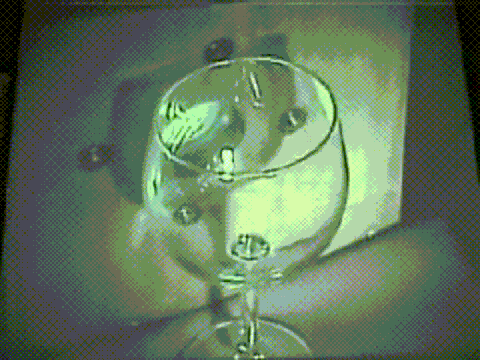

***

Ποτήρια, κούνιες, ή κρεμαστές γέφυρες θα αποτελούσαν ωραία παραδείγματα εξάσκησης μέσω εργαστηρίου αλλά πάνω απ'όλα βαζουμε τη σωματική σας ακεραιότητα 😄.

Θα μελετήσουμε λοιπόν το συντονισμό μέσω της ομιλίας, όπου το σύστημα των {φωνητικών χορδών+φωνητικής οδού+χειλιών} αποτελεί έναν εξαναγκασμένο ταλαντωτή και το αντίστοιχο φαινόμενο ονομάζεται **φωνοσυντονισμός (formant)**! Οι πνεύμονες αναλαμβάνουν την παροχή εξωτερικής ενέργειας όταν εκφέρετε ένα φώνημα όπως τα /α/, /ε/, /ι/, /ο/, /ου/. Το σύστημα της φωνητικής οδού (φάρυγγας, γλώσσα, στόμα, μάγουλα, δόντια) αλλάζει κάθε φορά που εκφέρετε ένα διαφορετικό φώνημα, ενώ οι φωνητικές σας χορδές (ο διεγέρτης, όπως αναφέρθηκε παραπάνω) απλά ταλαντώνονται χωρίς καμία σχεδόν διαφορά ανάμεσα σε αυτά τα φωνήματα. 

Για του λόγου το αληθές, δοκιμάστε να εκφέρετε σταθερά για $3$ δευτερόλεπτα το φώνημα /α/ και παρατηρήστε πως τοποθετείτε τα χείλη σας και πως διατάσσετε τη στοματική κοιλότητά σας, σε σχέση με την εκφορά του φωνήματος /ου/: η αλλαγή της διάταξης του συστήματος της φωνητικής σας οδού (θέση γλώσσας, στοματικής κοιλότητας, χειλιών, κλπ) καθορίζει και τι τελικά θα πείτε: 
/α/ ή /ου/.

## Ζητούμενο 1:

Ηχογραφήστε τον εαυτό σας με το αγαπημένο σας πρόγραμμα (προτάσεις: Audacity, Wavesurfer, ή όποιο άλλο, ακόμα κι από το κινητό σας) με βάση τα παρακάτω:
* Στις παραμέτρους της ηχογράφησής σας επιλέξτε συχνότητα δειγματοληψίας $16000$ Hz και μονοκαναλική ηχογράφηση (όχι stereo). 
* Στην ηχογράφησή σας εκφέρετε το φώνημα /α/ **σταθερά** για $2-3$ δευτερόλεπτα (όπως θα κάνατε στον ΩΡΛ).
* Είναι καλή ιδέα να ξεκινήσετε την εκφορά και μετά να ξεκινήσετε την ηχογράφηση, ώστε να αποφύγετε τμήματα αρχικής σιωπής που θα αλλοιώσει την ανάλυση που ακολουθεί παρακάτω. 
* Τερματίστε την ηχογράφηση αρκετά πριν εξαντληθείτε. 
* Αποθηκεύστε το παραγόμενο αρχείο σε μορφή .WAV και ονομάστε το 'my_a.wav', και τοποθετήστε το στον ίδιο κατάλογο με το παρόν notebook αρχείο.

Αν δεν τα καταφέρετε, σας δίνεται μια ηχογράφηση από τον καθηγητή σας στο site του μαθήματος αλλά συνίσταται **ένθερμα** να φτιάξετε τη δική σας.

---
---

Ας διαβάσουμε την ηχογράφησή μας με χρήση της συνάρτησης wavfile της βιβλιοθήκης scipy κι ας την οπτικοποιήσουμε.

In [ ]:
samplerate, signal = wavfile.read('./my_a.wav')                   # Ανάγνωση (νέου) αρχείου ηχογράφησης.
signal = signal / np.max(np.abs(signal))                          # Κανονικοποίηση.
time = np.arange(0, len(signal) / samplerate, 1 / samplerate)     # Άξονας χρόνου.
print(samplerate)

plt.figure(figsize=(14, 6))                                       # Εμφάνιση σήματος.
plt.plot(time, signal)                                            # Εμφάνιση σήματος.
plt.xlabel('Χρόνος')
plt.ylabel('Πλάτος')
plt.title('To /a/ μου')
# plt.show()                                                      # Εμφάνιση γραφήματος.

Το παραπάνω σχήμα σας δείχνει μια αναπαράσταση **πλάτους-χρόνου**: με άλλα λόγια, είναι μια συνάρτηση $x(t)$ για το παραγόμενο σήμα ομιλίας: μας δείχνει ένα ηλεκτρικό σήμα που αντιστοιχεί στην ταλάντωση των μορίων του αέρα - σε σχέση με την θέση ισορροπίας τους - κατά τη μεταφορά του κύματος της ομιλίας από το στόμα στο διάφραγμα του μικροφώνου. Αυτές οι τιμές που παρατηρείτε στο γράφημα εκφράζουν κατά κάποιο τρόπο την ένταση της φωνής μας για κάθε χρονική στιγμή της ηχογράφησης. 

Για να παρατηρήσουμε το φαινόμενο του φωνοσυντονισμού, θα πρέπει να το μετατρέψουμε σε μια αναπαράσταση **πλάτους-συχνότητας**! Το πως ακριβώς γίνεται αυτό είναι **τελείως εκτός** του σκοπού του μαθήματος, αλλά αν σας ενδιαφέρει αναζητήστε - ή, καλύτερα, ρωτήστε το διδάσκοντα - πληροφορίες σχετικά με τον Γρήγορο Μετασχηματισμό Fourier (Fast Fourier Transform).

Εκτελέστε τις παρακάτω γραμμές για να πάρετε ένα σχήμα που απεικονίζει μια δημοφιλή αναπαράσταση πλάτους-συχνότητας, που όμως δεν είναι ακριβώς βολική για την εύρεση των περιοχών φωνοσυντονισμού αλλά παρ'όλα αυτά είναι χρήσιμη.

In [ ]:
NFFT = 2048
X = np.fft.fft(signal, NFFT)
Freq = np.arange(0, samplerate/2, samplerate/NFFT)
plt.figure(figsize=(14, 6))
plt.plot(Freq, 20*np.log10(np.abs(X[0:NFFT//2])))
plt.xlabel('Συχνότητα f (Hz)')
plt.ylabel('Πλάτος')
plt.title('Φάσμα πλάτους')
plt.grid()
plt.autoscale(enable=True, axis='x', tight=True)
# plt.show()

Αυτό που βλέπετε παραπάνω ονομάζεται **φάσμα πλάτους**, και είναι ακριβώς ένα γράφημα πλάτους-συχνότητας.

Όμως, αυτές οι λεπτές "μυτερές" κορυφές που παρατηρείτε (ειναι εμφανεστερες στο αριστερό τμήμα του γραφήματος) **ΔΕΝ** αποτελούν τιμές πλάτους των συχνοτήτων φωνοσυντονισμού. Οι λεπτές αυτές κορυφές σχετίζονται με τις **αρμονικές συχνότητες** της φωνής μας. Οι συχνότητες φωνοσυντονισμού μπορούν μόνο χονδρικά να υπολογιστούν από το παραπάνω γράφημα ως οι περιοχές όπου οι "μυτερές" κορυφές σχηματίζουν ομάδες που συλλεκτικά σχηματίζουν κάποιο "λόφο" - μια υπερβολικά απλοϊκή περιγραφή για λόγους κατανόησης. Ας μη βασιστούμε σε αυτή. Θέλουμε κάτι καλύτερο! :)

Παρακάτω σας δίνεται κώδικας για μια καλύτερη εύρεση των συχνοτήτων φωνοσυντονισμού. **Η επεξήγηση του κώδικα είναι επίσης εντελώς εκτός σκοπού του μαθήματος**, αλλά αν σας ενδιαφέρει μπορείτε να ρωτήσετε το διδάσκοντα. 

**Διαβάστε και ξεχάστε το: ON**

Η μέθοδος που ακολουθείται ονομάζεται **Γραμμική Πρόβλεψη (Linear Prediction)**. Ο ήχος και η φωνή κωδικοποιείται μέσω των συντελεστών της γραμμικής πρόβλεψης όταν μεταδίδεται πάνω από κάποια δίκτυα κινητής τηλεφωνίας, καθώς και στο πρότυπο MPEG4. Οι συντελεστές αυτοί δεν είναι κάτι περισσότερο από αριθμούς που σχετίζονται με κάποιο (όχι και τόσο οικείο σε σας) πολυώνυμο σχετικά μεγάλου βαθμού, π.χ. 

$$A(z) = a_Pz^{-P} + a_{P-1}z^{-(P-1)} + \cdots + a_1 z^{-1} + a_0$$ 

Οι συντελεστές $a_i$, $0 < i < P$ είναι οι λεγόμενοι συντελεστές γραμμικής πρόβλεψης. Οι συντελεστές του πολυωνύμου αυτού χρησιμοποιούνται για να προβλέψουν ένα οποιοδήποτε δείγμα $x[n]$ της ηχογράφησής μας από τα $P$ προηγούμενα με το ελάχιστο δυνατό σφάλμα ως εξής: 

$$x[n] = - \sum_{i=1}^{p} a_i \cdot x[n-i] + e[n]$$

με $e[n]$ το ελάχιστο δυνατό "υπόλειμμα" (residual) μεταξύ της πρόβλεψής μας και της ακριβούς τιμής του $n-$οστού δείγματος.

Το πολυώνυμο αυτό μπορεί να μας δώσει μια επιπλέον αναπαράσταση πλάτους-συχνότητας και να μας βοηθήσει να εντοπίσουμε τις περιοχές φωνοσυντονισμού. Δείτε παρακάτω πως, εκτελώντας το επόμενο κελί.

**Διαβάστε και ξεχάστε το: OFF**

---


In [ ]:
def make_matrix_X(x, p):
    
    n = len(x)
    xz = np.concatenate([x[::-1], np.zeros(p)])

    X = np.zeros((n - 1, p))
    for i in range(n - 1):
        offset = n - 1 - i
        X[i, :] = xz[offset: offset + p]
    return X


def solve_lpc(x, p):
    
    b = x[1:]
    X = make_matrix_X(x, p)
    a = np.linalg.lstsq(X, b.T, rcond=None)[0]
    e = b - np.dot(X, a)
    g = np.var(e)
    return [a, g]


signal_pe = scipy.signal.lfilter([1, -0.97], 1, signal)     # Φίλτρο προέμφασης (pre-emphasis filter).
X = np.fft.fft(signal_pe, NFFT)                             # Φάσμα φιλτραρισμένου σήματος.
a, g = solve_lpc(signal_pe, 18)                             # Γραμμική Πρόβλεψη.
a = np.concatenate(([1], -a), axis=0)                       # Φτιάχνουμε το πολυώνυμο της γραμμικής πρόβλεψης.

f, h = scipy.signal.freqz(1, a, fs=samplerate)              # Υπολογίζουμε την περιβάλλουσα του προηγούμενου σχήματος...
                                                            # που μας δείχνει τις περιοχές φωνοσυντονισμού.
plt.figure(figsize=(14, 6))                                 # Τυπώνουμε μαζί τα δυο γραφήματα.
plt.plot(Freq, 20*np.log10(np.abs(X[0:NFFT//2])))
plt.plot(f, 20*np.log10(np.abs(h)))
plt.xlabel('Συχνότητα f (Hz)')
plt.ylabel('Πλάτος (dB)')
plt.title('Φασματική περιβάλλουσα')
plt.grid()
plt.autoscale(enable=True, axis='x', tight=True)
plt.legend(["Φάσμα", "Περιβάλλουσα"], loc="upper right")
# plt.show()

## Ζητούμενο 2:

Παρατηρήστε το γράφημα που παράγει ο παραπάνω κώδικας. Θα δείτε δυο γραφικές παραστάσεις: μια που απεικονίζει το αρμονικό περιεχόμενο της ομιλίας σας (την οποία είδατε και πριν), και ονομάσαμε **φάσμα πλάτους**, και άλλη μια, πολύ πιο ομαλή, που έχουμε σχεδιάσει "επάνω" στην προηγούμενη, και μας πληροφορεί για τις περιοχές φωνοσυντονισμού. Η δεύτερη αυτή καμπύλη ονομάζεται **φασματική περιβάλλουσα**. Παρατηρήστε ότι και τα δυο γραφήματα έχουν σχεδιαστεί σε λογαριθμική κλίμακα, ώστε να μπορείτε ευκολότερα να παρατηρείτε τι συμβαίνει.

Γράψτε παρακάτω μια **εκτίμηση** για τις **συχνότητες** φωνοσυντονισμού που παρατηρείτε, με τη σειρά που αυτές εμφανίζονται και όπως αυτές ορίζονται από τα ισχυρά υψώματα (τοπικά μέγιστα) στη φασματική περιβάλλουσα που "σκεπάζει" το φάσμα πλάτους. 

Σημειώστε ότι στη δική σας ηχογράφηση (όπως και σε αυτή που σας δίνεται) μπορεί να παρατηρούνται περισσότεροι από τέσσερις φωνοσυντονισμοί. Γράψτε μια εκτίμηση για τις συχνότητες των τεσσάρων πρώτων (όπως τους συναντάτε από αριστερά προς τα δεξιά στο γράφημα). Κάντε edit το παρακάτω κελί.

* Συχνότητα 1ου Φωνοσυντονισμού:   ~ 663 Hz


* Συχνότητα 2ου Φωνοσυντονισμού:   ~ 1282 Hz


* Συχνότητα 3ου Φωνοσυντονισμού:   ~ 2416 Hz


* Συχνότητα 4ου Φωνοσυντονισμού:   ~ 3875 Hz

#### Προαιρετικό: Όποιος/α ενδιαφέρεται μπορεί να ηχογραφήσει επιπλέον φωνήματα, όπως το /ε/ ή το /ου/, ξανά για 2-3 δευτερόλεπτα, με τις ίδιες ρυθμίσεις ηχογράφησης, και να παρατηρήσει πως μεταβάλλονται οι παραπάνω φωνοσυντονισμοί. Ο διδάσκων θα χαρεί να ακούσει τις παρατηρήσει σας σε προσωπικό διάλογο (είτε δια ζώσης είτε μέσω e-mail).

***
***
## Παραδοτέα:
*** 
### Μετονομάστε το **συμπληρωμένο και με εκτελεσμένο κάθε κελί κώδικα** notebook σε 

## *ΗΥ112-HW4-Python-CSDXXXX.ipynb*, 

### με *XXXX* ο αριθμός μητρώου σας. 

### Αν είστε με προσωρινό κωδικό λόγω μεταγραφής, τότε ονομάστε το αρχείο σας 

## *ΗΥ112-HW4-Python-mtgXXXX.ipynb*, 

### με *XXXX* ο προσωρινός αριθμός μητρώου σας.

### Στείλτε το μετονομασμένο notebook ως επισυναπτόμενο αρχείο με e-mail στο sisamaki@csd.uoc.gr . 

### Στο e-mail θα αναγράφετε:

### - Τίτλος: [ΗΥ112] 4ο εργαστήριο Python

### και στο σώμα του e-mail τα παρακάτω: 

### - Ονοματεπώνυμο
### - ΑΜ

### ΠΡΟΣΕΞΤΕ: Το παραδοτέο αρχείο σας πρέπει να έχει extension .ipynb, και ΟΧΙ κάτι άλλο!!